# VWAP Events 01 — does a VWAP touch precede a violent move?

Pre-registration: `discussions/VWAP_Events/001_claude_branch_preregistration.md`. Parameters, windows and gates are fixed in
`src/data_engineering/modeling/vwap_events.py` (`registration()` below).

- **Data:** Binance USD-M perpetual 1-minute klines (`tools/download_binance_um_klines.py`); VWAP $=\sum \text{quote vol}/\sum \text{vol}$ since the anchor (exact).
- **Anchors:** session VWAP anchored at 08:00 UTC (Deribit expiry) and 4-hour VWAP (00/04/…/20 UTC).
- **Event:** the bar's range contains the VWAP known at its open, after 15 closes on one side with at least one $\ge 1\,\hat\sigma\sqrt{15}$ away.
- **Outcome (primary):** $y=\log R_{15}-\text{median}_{\text{hour}}\log R_{15}$, with $R_k=\sqrt{\sum_{i=1}^{k} r_{t+i}^2}\,/\,(\hat\sigma_{t-1}\sqrt{k})$.
- **Placebos:** the same VWAP shifted by a constant offset per window; a VWAP of the same period anchored at a random phase.
- **Decision (test window from 2026-04-01):** per anchor, $\Delta=\bar y_{\text{real}}-\bar y_{\text{placebo}}$ must have CI lower bound $>0$ (Bonferroni over 4 comparisons) **and** $e^{\Delta}\ge 1.10$, against both placebos.

Environment: `VE01_ASSETS` (comma list), `VE01_N_PLACEBO` (default 20), `BINANCE_UM_DIR` (default `<parent of DERIBIT_DATA_ROOT>/Binance`), `VE01_SYNTHETIC=1` (synthetic smoke run, outputs to a temp dir).

In [7]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import vwap_events as ve

SYNTHETIC = os.getenv('VE01_SYNTHETIC', '').strip() == '1'
ASSETS = [a.strip().upper() for a in os.getenv('VE01_ASSETS', ','.join(ve.ASSETS)).split(',') if a.strip()]
P = replace(ve.Params(), n_placebo=int(os.getenv('VE01_N_PLACEBO', str(ve.Params().n_placebo))))
if SYNTHETIC:
    BIN_DIR = None
    OUT = Path(tempfile.mkdtemp(prefix='ve01_'))
else:
    BIN_DIR = Path(os.getenv('BINANCE_UM_DIR') or Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance').expanduser().resolve()
    OUT = PROJECT_ROOT / 'notebooks' / 'VWAP_Events' / '01'
OUT.mkdir(parents=True, exist_ok=True)
REG = ve.registration(P)
print('VWAP Events 01 |', ve.VERSION, '| synthetic' if SYNTHETIC else f'| data {BIN_DIR}', '| out', OUT)
print(json.dumps({k: REG[k] for k in ('m_approach', 'd_approach', 'cooldown', 'horizons', 'primary_h', 'n_placebo',
                                       'ci_level', 'min_effect', 'test_start')}, default=str))

VWAP Events 01 | vwap_events v1.0 | data D:\MarketData\Binance | out D:\Projects\deribit_market_data\notebooks\VWAP_Events\01
{"m_approach": 15, "d_approach": 1.0, "cooldown": 15, "horizons": [5, 15, 30, 60], "primary_h": 15, "n_placebo": 20, "ci_level": 0.9875, "min_effect": 1.1, "test_start": "2026-04-01 00:00:00+00:00"}


## 1. Data and events (real touches and placebo touches)

In [8]:
events, coverage = [], []
for i, a in enumerate(ASSETS):
    t0 = time.time()
    if SYNTHETIC:
        df = ve.synthetic_klines(n_days=180, seed=10 + i, start='2025-12-01')
    else:
        path = BIN_DIR / f'{a}USDT_um_1m.parquet'
        if not path.exists():
            print(f'{a}: no Binance file at {path} -> skipped'); continue
        df = pd.read_parquet(path, columns=['open_time', 'high', 'low', 'close', 'volume', 'quote_volume'])
    ev, info = ve.run_asset(df, a, P)
    events.append(ev); coverage.append(info)
    print(f'{a}: {info["bars"]:,} bars, {len(ev):,} event rows, {time.time() - t0:.0f}s')
EV = pd.concat(events, ignore_index=True)
coverage = pd.DataFrame(coverage); display(coverage)
counts = EV.groupby(['anchor', 'window', 'kind', 'asset']).size().unstack('asset').fillna(0).astype(int)
display(counts)

BTC: 1,067,040 bars, 390,502 event rows, 32s
ETH: 1,067,040 bars, 397,971 event rows, 30s
SOL: 1,067,040 bars, 404,706 event rows, 31s
XRP: 1,067,040 bars, 405,776 event rows, 30s
AVAX: no Binance file at D:\MarketData\Binance\AVAXUSDT_um_1m.parquet -> skipped
TRX: no Binance file at D:\MarketData\Binance\TRXUSDT_um_1m.parquet -> skipped
HYPE: no Binance file at D:\MarketData\Binance\HYPEUSDT_um_1m.parquet -> skipped


,asset,first_bar,last_bar,bars,missing_bars,all_bar_mean_y_primary
0,BTC,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,0,-inf
1,ETH,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,0,-inf
2,SOL,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,0,-inf
3,XRP,2024-10-01 00:00:00+00:00,2026-10-11 23:59:00+00:00,1067040,0,-inf


asset                          BTC     ETH     SOL     XRP
anchor       window kind                                  
h4           dev    offset   35348   37339   36964   36569
                    phase   123154  123255  128861  129812
                    real      6003    6093    6394    6322
             test   offset   13003   13356   13123   13292
                    phase    40881   42015   43169   43767
                    real      2000    2054    2149    2157
session_0800 dev    offset   46313   46954   47910   46485
                    phase    76022   77519   76548   78311
                    real      3784    3904    3867    3962
             test   offset   16235   16091   16385   16651
                    phase    26471   28026   27944   27145
                    real      1288    1365    1392    1303

## 2. Primary readout — $y_{15}$, real vs each placebo, pooled assets

`ratio` $=e^{\Delta}$: how much larger the time-of-day-normalised 15-minute realised volatility is after a real touch than after a placebo touch. CI at the Bonferroni level; bootstrap over UTC days.

In [9]:
primary = ve.readout(EV, P)
display(primary.round(4))
dec = ve.decision(primary)
print('DECISION (test window):'); display(dec)

,anchor,window,placebo,outcome,n_real,n_placebo,days,mean_real,mean_placebo,delta,lo,hi,ratio,G1,G2
0,h4,dev,offset,y15,24812,146220,547,0.0591,0.2522,-0.1931,-0.2045,-0.1812,0.8244,False,False
1,h4,dev,phase,y15,24812,505082,547,0.0591,0.0635,-0.0044,-0.0104,0.0016,0.9956,False,False
2,h4,test,offset,y15,8360,52774,194,0.0669,0.2548,-0.1879,-0.2094,-0.1672,0.8287,False,False
3,h4,test,phase,y15,8360,169832,194,0.0669,0.0715,-0.0046,-0.0153,0.0072,0.9954,False,False
4,session_0800,dev,offset,y15,15517,187662,547,0.1090,0.1806,-0.0715,-0.0805,-0.0618,0.9310,False,False
5,session_0800,dev,phase,y15,15517,308400,547,0.1090,0.1125,-0.0034,-0.0098,0.0031,0.9966,False,False
6,session_0800,test,offset,y15,5348,65362,194,0.1274,0.1894,-0.0620,-0.0809,-0.0426,0.9399,False,False
7,session_0800,test,phase,y15,5348,109586,194,0.1274,0.1201,0.0073,-0.0050,0.0205,1.0073,False,False


DECISION (test window):


,anchor,G1_both,G2_both,pass
0,h4,False,False,False
1,session_0800,False,False,False


## 3. Secondary — horizons, absolute move, per asset, direction (descriptive, no gates)

In [10]:
rows = []
for k in P.horizons:
    for col, meas in ((f'y{k}', 'R (realised vol)'), (f'logM{k}', 'M (absolute move)')):
        r = ve.readout(EV, P, col=col); r['k'] = k; r['measure'] = meas; rows.append(r)
horizons = pd.concat(rows, ignore_index=True)
display(horizons[horizons['window'] == 'test'].pivot_table(index=['anchor', 'placebo', 'k'], columns='measure',
                                                            values='ratio', aggfunc='first').round(3))

by_asset = ve.readout(EV[EV['window'] == 'test'], P, by=('anchor', 'asset'))
display(by_asset[['anchor', 'asset', 'placebo', 'n_real', 'ratio', 'lo', 'hi']].round(4))

direction = ve.readout(EV, P, col=f'cross{P.primary_h}')
direction = direction.rename(columns={'mean_real': 'p_cross_real', 'mean_placebo': 'p_cross_placebo'})
display(direction[['anchor', 'window', 'placebo', 'n_real', 'p_cross_real', 'p_cross_placebo', 'delta', 'lo', 'hi']].round(4))

measure                  R (realised vol)
anchor       placebo k                   
h4           offset  5              0.000
                     15             0.829
                     30             0.863
                     60             0.899
             phase   15             0.995
                     30             0.998
                     60             1.001
session_0800 offset  5                inf
                     15             0.940
                     30             0.956
                     60             0.970
             phase   5                inf
                     15             1.007
                     30             1.010
                     60             1.008

,anchor,asset,placebo,n_real,ratio,lo,hi
0,h4,BTC,offset,2000,0.8287,-0.2175,-0.1595
1,h4,BTC,phase,2000,0.9880,-0.0316,0.0072
2,h4,ETH,offset,2054,0.7857,-0.2749,-0.2106
3,h4,ETH,phase,2054,0.9863,-0.0337,0.0049
4,h4,SOL,offset,2149,0.8393,-0.2009,-0.1503
5,h4,SOL,phase,2149,0.9933,-0.0231,0.0093
6,h4,XRP,offset,2157,0.8632,-0.1729,-0.1241
7,h4,XRP,phase,2157,1.0137,-0.0036,0.0335
8,session_0800,BTC,offset,1288,0.9335,-0.0972,-0.0381
9,session_0800,BTC,phase,1288,1.0036,-0.0202,0.0276


,anchor,window,placebo,n_real,p_cross_real,p_cross_placebo,delta,lo,hi
0,h4,dev,offset,24812,0.4943,0.4625,0.0318,0.0201,0.0423
1,h4,dev,phase,24812,0.4943,0.4947,-0.0003,-0.0090,0.0077
2,h4,test,offset,8360,0.4927,0.4535,0.0392,0.0180,0.0608
3,h4,test,phase,8360,0.4927,0.4979,-0.0052,-0.0198,0.0093
4,session_0800,dev,offset,15517,0.4825,0.4672,0.0153,0.0025,0.0277
5,session_0800,dev,phase,15517,0.4825,0.4874,-0.0049,-0.0151,0.0052
6,session_0800,test,offset,5348,0.4796,0.4610,0.0186,-0.0027,0.0420
7,session_0800,test,phase,5348,0.4796,0.4825,-0.0029,-0.0220,0.0150


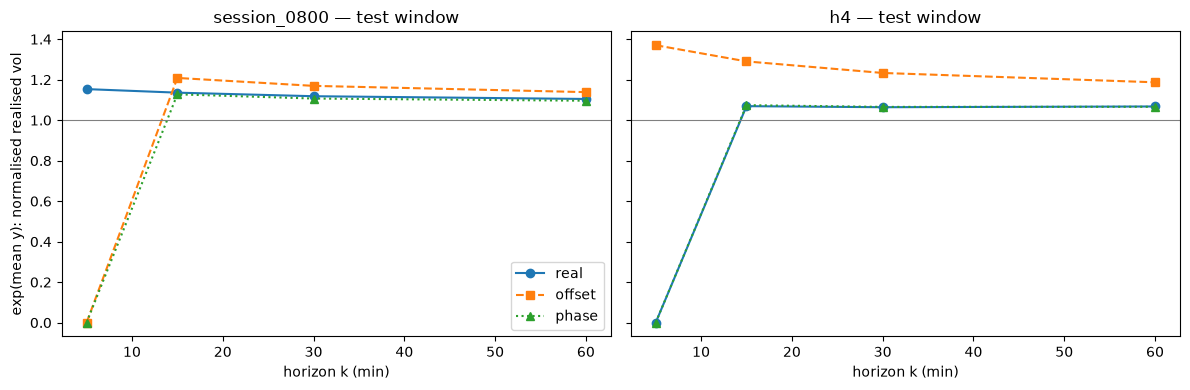

In [11]:
fig, axes = plt.subplots(1, len(P.anchors), figsize=(12, 4), sharey=True)
axes = np.atleast_1d(axes)
t = EV[EV['window'] == 'test']
for ax, an in zip(axes, [a.name for a in P.anchors]):
    for kind, st in (('real', '-o'), ('offset', '--s'), ('phase', ':^')):
        g = t[(t['anchor'] == an) & (t['kind'] == kind)]
        ax.plot(P.horizons, [np.exp(g[f'y{k}'].mean()) for k in P.horizons], st, label=kind)
    ax.axhline(1, color='grey', lw=0.8); ax.set_title(f'{an} — test window'); ax.set_xlabel('horizon k (min)')
axes[0].set_ylabel('exp(mean y): normalised realised vol'); axes[0].legend()
plt.tight_layout(); plt.show()

## 4. Save compact outputs

In [12]:
coverage.to_csv(OUT / '01_coverage.csv', index=False)
counts.reset_index().to_csv(OUT / '01_event_counts.csv', index=False)
primary.to_csv(OUT / '01_primary_readout.csv', index=False)
dec.to_csv(OUT / '01_decision.csv', index=False)
horizons.to_csv(OUT / '01_horizons.csv', index=False)
by_asset.to_csv(OUT / '01_by_asset_test.csv', index=False)
direction.to_csv(OUT / '01_direction.csv', index=False)
manifest = {'registration': REG, 'assets_run': list(coverage['asset']), 'synthetic': SYNTHETIC,
            'decision': dec.to_dict(orient='records'), 'run_utc': str(pd.Timestamp.now(tz='UTC'))}
(OUT / '01_manifest.json').write_text(json.dumps(manifest, indent=2, default=str), encoding='utf-8')
print('saved to', OUT, sorted(p.name for p in OUT.iterdir()))

saved to D:\Projects\deribit_market_data\notebooks\VWAP_Events\01 ['01_by_asset_test.csv', '01_coverage.csv', '01_decision.csv', '01_direction.csv', '01_event_counts.csv', '01_horizons.csv', '01_manifest.json', '01_primary_readout.csv']
